# Лабораторная 5. Свёрточные нейронные сети. Классификация изображений

**Задание.** Реализовать свёрточную сеть со свёрточными блоками двух видов:
а) `{Conv2d-ReLU-MaxPool}`; б) `{Conv2d-ReLU-Conv2d-ReLU-MaxPool}`.

Для выборки MNIST или FashionMNIST, или одной из выборок модуля `Datasets`
выбрать сочетание *некоторых* из следующих гиперпараметров, дающих наилучшее
качество классификации: 1) коэффициент обучения; 2) тип свёрточных блоков
(типы а или б) и их количество; 3) параметры свёртки (класс `Conv2d`):
размер фильтра `kernel_size` и шаг `stride`; 4) параметры пуллинга (класс
`MaxPool2d`): размер окна `kernel_size` и шаг `stride`.

Оценить количество эпох, достаточное для классификации с точностью (метрика
accuracy) не меньшей 90% для свёрточной сети с выбранным сочетанием указанных
параметров.

Дополнительно (по выбору): варьирование параметров обучения, других
гиперпараметров модели, использование различных оптимизаторов.

## 1. Теория

### Данные

MNIST: изображения $28 \times 28$ в градациях серого, 10 классов. Из обучающей
части MNIST берутся три непересекающиеся подвыборки: 3000 изображений для
обучения при переборе гиперпараметров, 1500 отложенных для их оценки и 12000 для
обучения финальной модели. Финальная модель проверяется на тестовой выборке MNIST
из 10000 изображений, которая в переборе не участвует. Яркости делятся на 255 и
нормируются стандартными для MNIST значениями $\mu = 0.1307$, $\sigma = 0.3081$.

### Свёртка и пуллинг

Свёртка применяет одно и то же ядро размера $k \times k$ ко всем положениям
карты признаков. Для входа $X$ с $c_{\text{in}}$ каналами выходной канал с ядром
$K$ и смещением $b$ равен

$$Y_{ij} = \sum_{c=1}^{c_{\text{in}}}\sum_{u=0}^{k-1}\sum_{v=0}^{k-1}
X_{c,\; i s + u,\; j s + v}\,K_{c u v} + b,$$

где $s$ это шаг (`stride`), а вход заранее дополнен нулями ширины $p$ с каждой
стороны. Слой с $c_{\text{out}}$ выходными каналами имеет $c_{\text{out}}$ таких
ядер. Пуллинг `MaxPool2d` берёт максимум по окну $k \times k$ с шагом $s$ в
каждом канале отдельно. Для входа $n \times n$ размер выхода у обоих слоёв

$$n_{\text{out}} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1 .$$

В свёртках $p = \lfloor k/2 \rfloor$, поэтому при $s = 1$ размер карты не
меняется, в пуллинге $p = 0$. Число параметров свёрточного слоя равно
$k^2 c_{\text{in}} c_{\text{out}} + c_{\text{out}}$, где $c_{\text{in}}$ и
$c_{\text{out}}$ это числа входных и выходных каналов.

### Сеть

Сеть состоит из $n$ блоков одного вида и полносвязного слоя на 10 выходов, в
блоке номер $i$ свёртки дают $8i$ каналов. Блок а) `Conv2d-ReLU-MaxPool2d`,
блок б) `Conv2d-ReLU-Conv2d-ReLU-MaxPool2d`. Шаг `stride` задаётся у первой
свёртки блока, у второй свёртки блока б) он равен 1. Если карта признаков стала
меньше окна пуллинга, пуллинг в блоке не ставится. ReLU применяется к каждому
элементу: $\mathrm{ReLU}(t) = \max(0, t)$.

### Функция потерь, обучение и мера качества

Выходы сети $t_0, \ldots, t_9$ переводятся мягким максимумом в вероятности цифр
$p_c = e^{t_c} / (e^{t_0} + \dots + e^{t_9})$. Функция потерь - перекрёстная
энтропия, средний минус логарифм вероятности верной цифры:
$L = -\frac1n\sum_k \log p_{y_k}(x_k)$. Градиент $L$ по весам torch находит
методом обратного распространения ошибки.

Обучение - стохастический градиентный спуск: на каждой эпохе объекты
перемешиваются и делятся на батчи, после каждого батча делается шаг по градиенту
$g$ функции потерь на батче. В SGD с моментом 0.9 шаг накапливает предыдущие
направления:

$$v \leftarrow 0.9\,v + g, \qquad w \leftarrow w - \eta v .$$

В Adam вместо $g$ берётся скользящее среднее градиентов, а шаг по каждому весу
делится на корень из скользящего среднего квадратов его градиентов, поэтому веса
с большими и малыми градиентами меняются с близкой скоростью.

Качество: доля верных ответов
$\mathrm{accuracy} = \frac1n \sum_k [\,\hat y_k = y_k\,]$.

### Что перебирается

| Этап | Гиперпараметр | Значения |
|---|---|---|
| 1 | коэффициент обучения | $0.005$, $0.01$, $0.05$, $0.1$ |
| 1 | тип блока | а, б |
| 1 | число блоков | 1, 2 |
| 1 | `kernel_size` свёртки | 3, 5, 7 |
| 2 | `stride` свёртки | 1, 2 |
| 2 | `kernel_size` пуллинга | 2, 3 |
| 2 | `stride` пуллинга | 2, 3 |
| 3 | оптимизатор | SGD с моментом 0.9, Adam с коэффициентом обучения $0.001$ и $0.003$ |

На этапе 1 шаг свёртки 1, пуллинг с окном 2 и шагом 2, оптимизатор SGD с
моментом 0.9. На этапах 2 и 3 остальные параметры берутся лучшими с предыдущего
этапа. Каждое сочетание обучается 6 эпох батчами по 64, его качество это
accuracy на отложенной выборке после последней эпохи. Финальная модель с
выбранным сочетанием обучается 12 эпох, accuracy на тестовой выборке считается
после каждой эпохи.

## 2. Данные

In [1]:
import os
import struct
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(20260905)
torch.backends.cudnn.deterministic = True  # одинаковые числа при перезапуске на GPU
RNG = np.random.default_rng(20260905)
plt.rcParams['figure.dpi'] = 110

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'torch {torch.__version__}, устройство: {DEVICE}')

torch 2.11.0+cu128, устройство: cuda


In [2]:
def read_idx(path):
    with open(path, 'rb') as f:
        magic, = struct.unpack('>I', f.read(4))
        dims = struct.unpack('>' + 'I' * (magic & 0xff), f.read(4 * (magic & 0xff)))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(dims)


def mnist_dir():
    for c in [os.environ.get('MNIST_DIR'),
              '../../bachelor/Perceptron/data_generation/MNIST/raw',
              'data/MNIST/raw']:
        if c and Path(c, 'train-images-idx3-ubyte').exists():
            return Path(c)
    raise FileNotFoundError('не найдены файлы MNIST')


D = mnist_dir()
Xtr_all = read_idx(D / 'train-images-idx3-ubyte')
ytr_all = read_idx(D / 'train-labels-idx1-ubyte')
Xte_all = read_idx(D / 't10k-images-idx3-ubyte')
yte_all = read_idx(D / 't10k-labels-idx1-ubyte')

MEAN, STD = 0.1307, 0.3081


def to_tensor(X, y):
    """Изображения в тензор (N, 1, 28, 28) с нормировкой, метки в long."""
    xt = torch.tensor(X, dtype=torch.float32).unsqueeze(1) / 255.0  # ось 1 это канал
    xt = (xt - MEAN) / STD
    # .to(DEVICE) переносит тензоры на видеокарту, если она есть
    return xt.to(DEVICE), torch.tensor(y, dtype=torch.long).to(DEVICE)


# три непересекающиеся части обучающей выборки: перебор, отложенная, финальная модель
perm = RNG.permutation(len(Xtr_all))
idx_grid, idx_val, idx_big = perm[:3000], perm[3000:4500], perm[4500:16500]
Xg, yg = to_tensor(Xtr_all[idx_grid], ytr_all[idx_grid])
Xv, yv = to_tensor(Xtr_all[idx_val], ytr_all[idx_val])
print(f'перебор: обучающая {tuple(Xg.shape)}, отложенная {tuple(Xv.shape)}')

перебор: обучающая (3000, 1, 28, 28), отложенная (1500, 1, 28, 28)


## 3. Сеть и обучение

In [3]:
class ConvNet(nn.Module):
    """Свёрточная сеть из блоков двух видов.
    block='a': Conv-ReLU-MaxPool; block='b': Conv-ReLU-Conv-ReLU-MaxPool."""

    def __init__(self, block='a', n_blocks=2, ks=3, stride=1,
                 pool_k=2, pool_s=2, channels=8):
        super().__init__()
        layers, c_in, size = [], 1, 28  # size это текущий размер карты признаков
        for i in range(n_blocks):
            c_out = channels * (i + 1)
            pad = ks // 2
            layers += [nn.Conv2d(c_in, c_out, ks, stride, pad), nn.ReLU()]
            size = (size + 2 * pad - ks) // stride + 1  # формула размера выхода
            if block == 'b':
                layers += [nn.Conv2d(c_out, c_out, ks, 1, pad), nn.ReLU()]
            if size >= pool_k:  # пуллинг возможен, пока карта не меньше окна
                layers += [nn.MaxPool2d(pool_k, pool_s)]
                size = (size - pool_k) // pool_s + 1
            c_in = c_out
        self.features = nn.Sequential(*layers)  # слои применяются по порядку
        self.out_size = size
        self.classifier = nn.Linear(c_in * size * size, 10)

    def forward(self, x):
        # flatten(1) вытягивает карту признаков в вектор, сохраняя ось объектов
        return self.classifier(self.features(x).flatten(1))

In [4]:
def evaluate(model, X, y, batch=512):
    """Доля верных ответов, считается батчами."""
    model.eval()
    correct = 0
    with torch.no_grad():  # при оценке градиенты не нужны
        for s in range(0, len(X), batch):
            correct += (model(X[s:s + batch]).argmax(1) == y[s:s + batch]).sum().item()
    return correct / len(X)


def train_model(model, Xtr, ytr, Xval, yval, lr, epochs, optimizer='sgd', batch=64, seed=0):
    """Обучение; после каждой эпохи записывается accuracy на выборке Xval."""
    torch.manual_seed(seed)
    if optimizer == 'sgd':
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.CrossEntropyLoss()
    hist = []
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr), device=Xtr.device)  # новый порядок объектов
        for s in range(0, len(Xtr), batch):
            b = perm[s:s + batch]
            opt.zero_grad()  # обнуление градиентов прошлого шага
            lossf(model(Xtr[b]), ytr[b]).backward()  # градиенты функции потерь по весам
            opt.step()  # шаг оптимизатора
        hist.append(evaluate(model, Xval, yval))
    return np.array(hist)


def epochs_to_level(hist, level=0.90):
    """Номер первой эпохи, на которой accuracy достигла level, иначе None."""
    for i, acc in enumerate(hist, start=1):
        if acc >= level:
            return i
    return None

In [5]:
demo = ConvNet(block='b', n_blocks=2, ks=3)
print(demo)
print(f'\nразмер карты признаков перед классификатором: {demo.out_size} x {demo.out_size}')
print(f'число параметров: {sum(p.numel() for p in demo.parameters())}')

ConvNet(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU()
    (7): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU()
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Linear(in_features=784, out_features=10, bias=True)
)

размер карты признаков перед классификатором: 7 x 7
число параметров: 12002


## 4. Этап 1: коэффициент обучения, тип и число блоков, размер ядра

In [6]:
EPOCHS = 6


def try_config(stage, lr, block, n_blocks, ks, stride=1, pool_k=2, pool_s=2, optimizer='sgd'):
    """Обучение на подвыборке для перебора, accuracy на отложенной после EPOCHS эпох."""
    torch.manual_seed(20260905)
    model = ConvNet(block, n_blocks, ks, stride, pool_k, pool_s).to(DEVICE)  # веса на видеокарту
    hist = train_model(model, Xg, yg, Xv, yv, lr=lr, epochs=EPOCHS, optimizer=optimizer)
    return dict(stage=stage, lr=lr, block=block, n_blocks=n_blocks, ks=ks, stride=stride,
                pool_k=pool_k, pool_s=pool_s, optimizer=optimizer, acc=hist[-1],
                params=sum(p.numel() for p in model.parameters()))


rows = []
for lr in [0.005, 0.01, 0.05, 0.1]:
    for block in ['a', 'b']:
        for n_blocks in [1, 2]:
            for ks in [3, 5, 7]:
                rows.append(try_config(1, lr, block, n_blocks, ks))
stage1 = pd.DataFrame(rows)

# строки - коэффициент обучения, столбцы - тип блока, число блоков и размер ядра
table = stage1.pivot_table(index='lr', columns=['block', 'n_blocks', 'ks'], values='acc')
print(table.round(4).to_string())

best = stage1.loc[stage1['acc'].idxmax()]  # строка с наибольшей accuracy
print(f"\nлучшее: lr {best['lr']}, блок {best['block']}, блоков {best['n_blocks']}, "
      f"ядро {best['ks']}, accuracy {best['acc']:.4f}")

block          a                                               b                                        
n_blocks       1                       2                       1                       2                
ks             3       5       7       3       5       7       3       5       7       3       5       7
lr                                                                                                      
0.005     0.9180  0.9447  0.9460  0.9400  0.9540  0.9567  0.9307  0.9533  0.9547  0.9453  0.9500  0.9427
0.010     0.9327  0.9540  0.9593  0.9587  0.9693  0.9680  0.9433  0.9587  0.9533  0.9607  0.9360  0.9460
0.050     0.9500  0.9600  0.9407  0.9687  0.9580  0.9400  0.9473  0.9473  0.9127  0.1153  0.8727  0.1153
0.100     0.9273  0.9327  0.8600  0.9320  0.7913  0.1153  0.8707  0.8580  0.1153  0.1153  0.1153  0.1007

лучшее: lr 0.01, блок a, блоков 2, ядро 5, accuracy 0.9693


## 5. Этап 2: параметры свёртки и пуллинга

In [7]:
rows = []
for stride in [1, 2]:
    for pool_k in [2, 3]:
        for pool_s in [2, 3]:
            rows.append(try_config(2, float(best['lr']), best['block'], int(best['n_blocks']),
                                   int(best['ks']), stride, pool_k, pool_s))
stage2 = pd.DataFrame(rows)
print(stage2[['stride', 'pool_k', 'pool_s', 'acc', 'params']].round(4).to_string(index=False))

best = stage2.loc[stage2['acc'].idxmax()]
print(f"\nлучшее: stride свёртки {best['stride']}, окно пуллинга {best['pool_k']}, "
      f"шаг пуллинга {best['pool_s']}, accuracy {best['acc']:.4f}")

 stride  pool_k  pool_s    acc  params
      1       2       2 0.9693   11274
      1       2       3 0.9407    4874
      1       3       2 0.9640    9194
      1       3       3 0.9613    4874
      2       2       2 0.9260    4074
      2       2       3 0.8907    3594
      2       3       2 0.9473    3594
      2       3       3 0.9347    4074

лучшее: stride свёртки 1, окно пуллинга 2, шаг пуллинга 2, accuracy 0.9693


## 6. Этап 3: оптимизатор

In [8]:
rows = []
for optimizer, lr in [('sgd', float(best['lr'])), ('adam', 0.001), ('adam', 0.003)]:
    rows.append(try_config(3, lr, best['block'], int(best['n_blocks']), int(best['ks']),
                           int(best['stride']), int(best['pool_k']), int(best['pool_s']), optimizer))
stage3 = pd.DataFrame(rows)
print(stage3[['optimizer', 'lr', 'acc']].round(4).to_string(index=False))

best = stage3.loc[stage3['acc'].idxmax()]
pd.concat([stage1, stage2, stage3], ignore_index=True).to_csv('results.csv', index=False)

optimizer    lr    acc
      sgd 0.010 0.9693
     adam 0.001 0.9573
     adam 0.003 0.9673


## 7. Число эпох до accuracy 90% для выбранного сочетания

выбранное сочетание:
block           a
n_blocks        2
ks              5
stride          1
pool_k          2
pool_s          2
optimizer     sgd
lr           0.01



эпох до accuracy не меньше 90% на тестовой выборке: 1
accuracy на тестовой выборке после 12 эпох: 0.9822


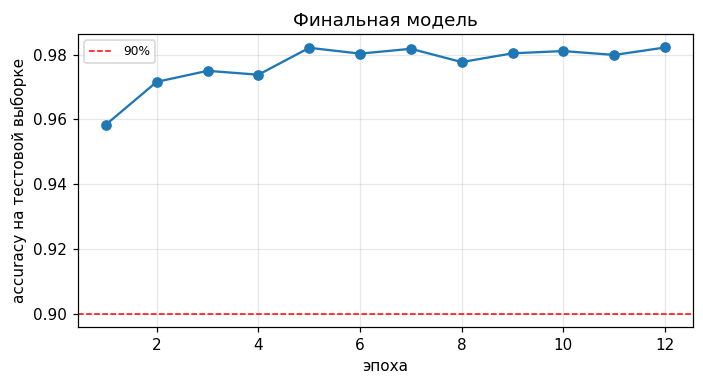

In [9]:
print('выбранное сочетание:')
print(best[['block', 'n_blocks', 'ks', 'stride', 'pool_k', 'pool_s', 'optimizer', 'lr']].to_string())

Xb, yb = to_tensor(Xtr_all[idx_big], ytr_all[idx_big])
Xt, yt = to_tensor(Xte_all, yte_all)

torch.manual_seed(20260905)
final = ConvNet(best['block'], int(best['n_blocks']), int(best['ks']), int(best['stride']),
                int(best['pool_k']), int(best['pool_s'])).to(DEVICE)
hist = train_model(final, Xb, yb, Xt, yt, lr=float(best['lr']), epochs=12,
                   optimizer=best['optimizer'])
print(f'\nэпох до accuracy не меньше 90% на тестовой выборке: {epochs_to_level(hist)}')
print(f'accuracy на тестовой выборке после 12 эпох: {hist[-1]:.4f}')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(range(1, len(hist) + 1), hist, marker='o')
ax.axhline(0.90, color='red', ls='--', lw=1, label='90%')
ax.set_xlabel('эпоха'); ax.set_ylabel('accuracy на тестовой выборке')
ax.set_title('Финальная модель'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()